In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import warnings
warnings.filterwarnings("ignore")


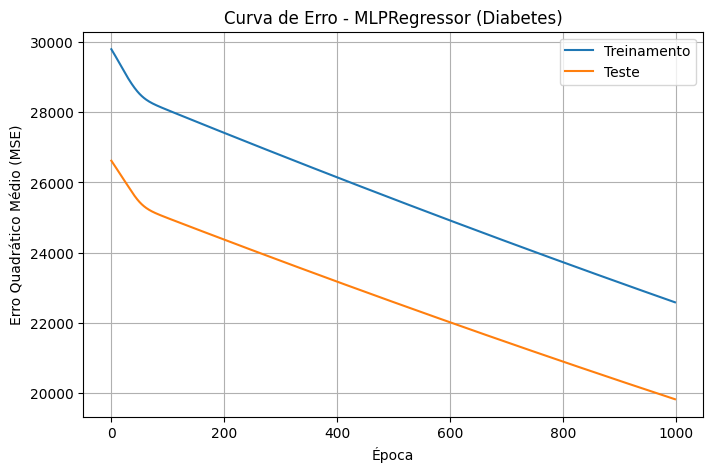

In [23]:
# Carregar o dataset
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target

# Dividir em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Padronizar os dados
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Criar o modelo com warm_start para treinar época por época
# Modelo
mlp = MLPRegressor(
    hidden_layer_sizes=(10, 30, 10),
    activation='tanh',
    solver='adam',
    alpha=1e-5,
    learning_rate_init=0.001,
    random_state=42,
    warm_start=True,
    max_iter=1
)

# Treinamento (época por época)
n_epochs = 1000
train_loss = []
test_loss = []

for epoch in range(n_epochs):
    mlp.fit(X_train, y_train)
    y_train_pred = mlp.predict(X_train)
    y_test_pred = mlp.predict(X_test)
    train_loss.append(mean_squared_error(y_train, y_train_pred))
    test_loss.append(mean_squared_error(y_test, y_test_pred))

# Curva de erro
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Treinamento")
plt.plot(test_loss, label="Teste")
plt.xlabel("Época")
plt.ylabel("Erro Quadrático Médio (MSE)")
plt.title("Curva de Erro - MLPRegressor (Diabetes)")
plt.legend()
plt.grid(True)
plt.show()



In [24]:
# Imprimir métricas de erro
print("----- ERROS DE REGRESSÃO -----")
print(f"Erro quadrático médio (MSE) - Treino: {mean_squared_error(y_train, y_train_pred):.2f}")
print(f"Erro quadrático médio (MSE) - Teste : {mean_squared_error(y_test, y_test_pred):.2f}")
print(f"Erro absoluto médio (MAE)   - Teste : {mean_absolute_error(y_test, y_test_pred):.2f}")
print(f"R² (coeficiente de determinação) - Teste: {r2_score(y_test, y_test_pred):.4f}")

# Comparar valores reais e preditos
resultados = pd.DataFrame({
    'Real': y_test,
    'Predito': y_test_pred
})

print("\n----- COMPARAÇÃO REAL vs. PREDITO -----")
print(resultados.head(10))  # Mostra as 10 primeiras linhas

----- ERROS DE REGRESSÃO -----
Erro quadrático médio (MSE) - Treino: 22586.85
Erro quadrático médio (MSE) - Teste : 19826.06
Erro absoluto médio (MAE)   - Teste : 120.53
R² (coeficiente de determinação) - Teste: -2.7421

----- COMPARAÇÃO REAL vs. PREDITO -----
    Real    Predito
0  219.0  25.243524
1   70.0  25.243524
2  202.0  25.243524
3  230.0  25.243524
4  111.0  25.243524
5   84.0  25.243524
6  242.0  25.243524
7  272.0  25.243524
8   94.0  25.243524
9   96.0  25.243524


In [27]:
mlp.coefs_[0]

array([[ 4.47120360e-02,  1.24502712e-01,  5.22843640e-02,
        -5.75998374e-02, -6.73069549e-02, -4.73337881e-02,
        -9.08907246e-02,  7.37084143e-02,  1.77923754e-02,
         1.05451513e-01],
       [-1.14214636e-01,  1.03456527e-01,  1.42766858e-01,
        -1.74337147e-01, -7.72858700e-02, -2.97778064e-02,
        -2.89085511e-02,  2.50391148e-02, -9.32174919e-03,
         2.83406603e-02],
       [-4.39339466e-02, -1.44076019e-01, -1.09567801e-02,
        -2.14350229e-02, -4.63704209e-02,  1.54325615e-02,
        -1.37827917e-01,  8.46674431e-02, -1.13636280e-02,
        -1.24817132e-01],
       [ 2.09820021e-02, -1.27063516e-01, -1.59391910e-01,
         1.96319218e-01,  1.17301337e-01,  3.74662943e-02,
        -7.51009937e-03, -9.82558232e-02, -8.47970590e-03,
        -6.40359555e-03],
       [-3.70651526e-01, -4.17300172e-02, -3.01250655e-01,
         1.14974917e-01, -6.19921878e-02, -6.68952497e-02,
         7.41566110e-02,  6.60275870e-02,  1.86429967e-01,
        -1.

In [26]:
print(mlp.intercepts_[0])

[-0.9260472   0.69134304 -0.81626921  0.48341161  0.97945449 -0.78432272
 -0.7046784   0.84826812 -0.86730556 -0.96687208]
